# CIFAR-10 DCGAN (Manual Baseline)
**CSYE 7380 — Applied Generative AI**

This notebook takes the Dense-only GAN from class (`gan.ipynb`, trained on MNIST) and converts the
**generator** and **discriminator** to a **Deep Convolutional GAN (DCGAN)**:

| | Class GAN (`gan.ipynb`) | This notebook |
|---|---|---|
| Data | MNIST 28×28×1 | **CIFAR-10 `automobile` only**, 32×32×3 |
| Generator | `Dense → Dense → Dense` | `Dense → Reshape → **Conv2DTranspose** (up-sampling)` |
| Discriminator | `Flatten → Dense → Dense` | strided **Conv2D** (down-sampling) |

I keep the original **class-based structure and `train_on_batch` training loop** on purpose so the change
is clearly *"same recipe, convolutional architecture"*. The end of the notebook demonstrates **controlling
the noise vector** (latent interpolation + per-dimension sweep).

> **Runtime:** built to run on **Google Colab** — set *Runtime → Change runtime type → GPU*, then *Run all*.
> It also runs locally. Sample grids are written to `./samples_manual/`.
>
> *This notebook is the **starting-point draft** for the handwritten "manual" version — adapt it into your own.*

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.models import Sequential, Model
from keras.layers import (Input, Dense, Reshape, Flatten, Dropout,
                          BatchNormalization, LeakyReLU,
                          Conv2D, Conv2DTranspose)
from keras.optimizers import Adam

print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))   # Colab: CUDA GPU; local M2: Metal
np.random.seed(42); tf.random.set_seed(42)

# output folder for sample grids (created wherever the notebook runs, incl. Colab)
SAMPLE_DIR = "samples_manual"
os.makedirs(SAMPLE_DIR, exist_ok=True)

TensorFlow 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load one CIFAR-10 class (`automobile`)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 328s 2us/step
Training images of 'automobile': (6000, 32, 32, 3)


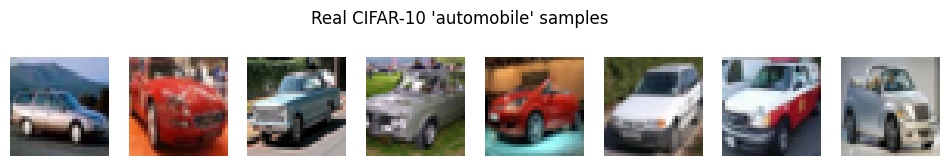

In [2]:
# CIFAR-10 class names (index -> label)
CLASS_NAMES = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']
TARGET_CLASS = 'automobile'
target_idx = CLASS_NAMES.index(TARGET_CLASS)

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
# combine train+test for more samples of the single class
X = np.concatenate([x_train, x_test], axis=0)
Y = np.concatenate([y_train, y_test], axis=0).flatten()

X = X[Y == target_idx]                      # keep only the target class
X = (X.astype(np.float32) - 127.5) / 127.5  # scale to [-1, 1]  (tanh output)
print(f"Training images of '{TARGET_CLASS}':", X.shape)

# preview a few real images
fig, axs = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axs):
    ax.imshow(0.5 * X[i] + 0.5); ax.axis('off')
fig.suptitle(f"Real CIFAR-10 '{TARGET_CLASS}' samples"); plt.show()

## 2. The DCGAN class
Same skeleton as the class `GAN`, with convolutional architectures.

**Generator** — grows a 100-d noise vector into a 32×32×3 image via transposed convolutions:
`Dense → Reshape(8,8,256) → Conv2DTranspose→16×16 → Conv2DTranspose→32×32 → Conv2D(3, tanh)`

**Discriminator** — shrinks a 32×32×3 image to a real/fake score via strided convolutions:
`Conv2D↓16 → Conv2D↓8 → Conv2D↓4 → Flatten → Dense(1, sigmoid)`

In [3]:
class DCGAN():
    def __init__(self, latent_dim=100):
        self.img_rows, self.img_cols, self.channels = 32, 32, 3
        self.img_shape = (self.img_rows, self.img_cols, self.channels)
        self.latent_dim = latent_dim

        # NOTE (Keras 3): give the discriminator and the combined model their OWN
        # optimizer instances. A single shared optimizer cannot be reused across two
        # different sets of trainable variables (D's weights vs. G's weights) and
        # raises "optimizer can only be called for the variables it was originally
        # built with" once we start toggling `trainable` in the loop.

        # Discriminator (own optimizer)
        self.discriminator = self.build_discriminator()
        self.discriminator.compile(loss='binary_crossentropy',
                                   optimizer=Adam(0.0002, 0.5), metrics=['accuracy'])

        # Generator
        self.generator = self.build_generator()

        # Combined model: train generator to fool a frozen discriminator (own optimizer)
        z = Input(shape=(self.latent_dim,))
        img = self.generator(z)
        self.discriminator.trainable = False
        valid = self.discriminator(img)
        self.combined = Model(z, valid)
        self.combined.compile(loss='binary_crossentropy', optimizer=Adam(0.0002, 0.5))

    def build_generator(self):
        model = Sequential(name="generator")
        model.add(Input(shape=(self.latent_dim,)))
        model.add(Dense(8 * 8 * 256))
        model.add(Reshape((8, 8, 256)))                              # 8x8
        model.add(BatchNormalization(momentum=0.8)); model.add(LeakyReLU(0.2))
        model.add(Conv2DTranspose(128, 4, strides=2, padding='same'))  # 16x16
        model.add(BatchNormalization(momentum=0.8)); model.add(LeakyReLU(0.2))
        model.add(Conv2DTranspose(64, 4, strides=2, padding='same'))   # 32x32
        model.add(BatchNormalization(momentum=0.8)); model.add(LeakyReLU(0.2))
        model.add(Conv2D(self.channels, 3, padding='same', activation='tanh'))
        model.summary()
        return model

    def build_discriminator(self):
        model = Sequential(name="discriminator")
        model.add(Input(shape=self.img_shape))
        model.add(Conv2D(64, 4, strides=2, padding='same'))   # 16x16
        model.add(LeakyReLU(0.2)); model.add(Dropout(0.3))
        model.add(Conv2D(128, 4, strides=2, padding='same'))  # 8x8
        model.add(LeakyReLU(0.2)); model.add(Dropout(0.3))
        model.add(Conv2D(256, 4, strides=2, padding='same'))  # 4x4
        model.add(LeakyReLU(0.2)); model.add(Dropout(0.3))
        model.add(Flatten())
        model.add(Dense(1, activation='sigmoid'))
        model.summary()
        return model

## 3. Training loop
Faithful to the class code: each step trains the discriminator on a half-batch of real + half-batch of
fake images, then trains the generator (via the combined model) to produce images the discriminator
labels as real.

> **⚠️ Keras 3 gotcha (important).** The in-class recipe sets `discriminator.trainable = False` once so the
> *combined* model only updates the generator. Under **Keras 3**, `trainable` is a global, immediate
> property of the model object — so that single line *also* freezes the standalone discriminator, and
> `discriminator.train_on_batch(...)` silently updates nothing (`"The model does not have any trainable
> weights"`). The discriminator never learns and the GAN collapses to colored noise.
>
> **Fix used here:** (1) give D and the combined model **separate optimizer instances**, and
> (2) **toggle** `discriminator.trainable` each step — `True` right before training D, `False` right
> before training G. (This re-tracing every step is part of why this baseline is slow; the
> `ai_generated/` version avoids the whole issue with a `GradientTape` step that explicitly applies
> generator gradients only to generator variables.)

In [4]:
def train(gan, X, steps=6000, batch_size=64, sample_interval=500, history=None):
    half = batch_size // 2
    if history is None: history = {'d_loss': [], 'd_acc': [], 'g_loss': []}
    for step in range(steps):
        # --- Train Discriminator ---
        # Keras 3: unfreeze D so its own train_on_batch actually updates weights.
        # (Without this, `discriminator.trainable=False` set for the combined model
        #  also freezes the standalone discriminator -> it never learns and the GAN
        #  collapses to noise.)
        gan.discriminator.trainable = True
        idx = np.random.randint(0, X.shape[0], half)
        real = X[idx]
        noise = np.random.normal(0, 1, (half, gan.latent_dim))
        fake = gan.generator.predict(noise, verbose=0)
        d_loss_real = gan.discriminator.train_on_batch(real, np.ones((half, 1)))
        d_loss_fake = gan.discriminator.train_on_batch(fake, np.zeros((half, 1)))
        d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)
        # --- Train Generator ---
        # Freeze D again so the combined model updates ONLY the generator.
        gan.discriminator.trainable = False
        noise = np.random.normal(0, 1, (batch_size, gan.latent_dim))
        g_loss = gan.combined.train_on_batch(noise, np.ones((batch_size, 1)))
        g_loss = float(np.atleast_1d(g_loss)[0])   # Keras 3 returns a list
        history['d_loss'].append(float(d_loss[0]))
        history['d_acc'].append(float(d_loss[1]))
        history['g_loss'].append(g_loss)
        if step % sample_interval == 0:
            print(f"{step:5d} [D loss {d_loss[0]:.3f} acc {100*d_loss[1]:.0f}%] [G loss {g_loss:.3f}]")
            sample_images(gan, step)
    return history

def sample_images(gan, step, r=4, c=4):
    noise = np.random.normal(0, 1, (r * c, gan.latent_dim))
    gen = 0.5 * gan.generator.predict(noise, verbose=0) + 0.5
    fig, axs = plt.subplots(r, c, figsize=(c, r))
    k = 0
    for i in range(r):
        for j in range(c):
            axs[i, j].imshow(np.clip(gen[k], 0, 1)); axs[i, j].axis('off'); k += 1
    fig.suptitle(f"step {step}")
    fig.savefig(f"{SAMPLE_DIR}/auto_{step:05d}.png", dpi=80, bbox_inches='tight')
    plt.show()

## 4. Train

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 16, 16, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 662,977 (2.53 MB)

 Trainable params: 662,977 (2.53 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16384)          │     1,654,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 3)      │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,313,859 (8.83 MB)

 Trainable params: 2,312,963 (8.82 MB)

 Non-trainable params: 896 (3.50 KB)

    0 [D loss 0.703 acc 33%] [G loss 0.578]


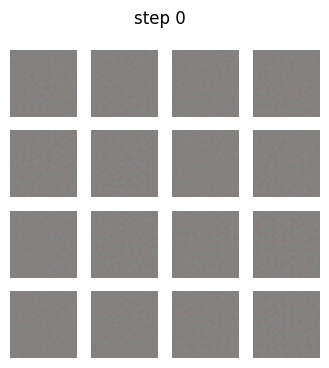

  500 [D loss 0.376 acc 84%] [G loss 3.104]


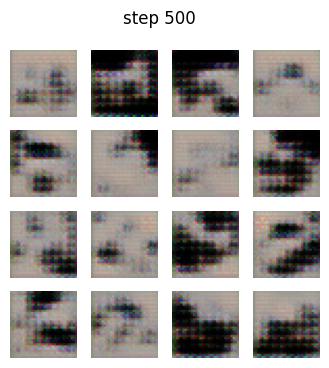

 1000 [D loss 0.477 acc 77%] [G loss 2.131]


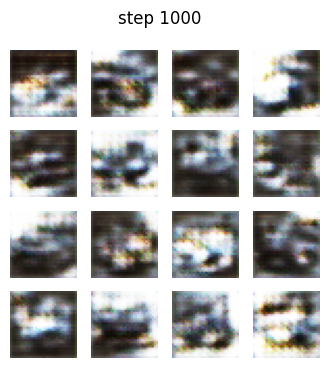

 1500 [D loss 0.545 acc 70%] [G loss 1.679]


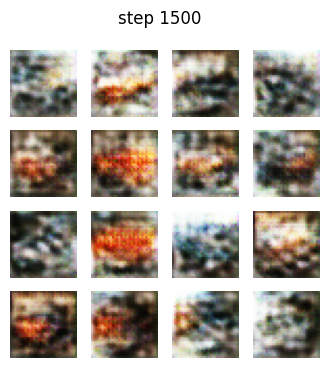

 2000 [D loss 0.576 acc 67%] [G loss 1.457]


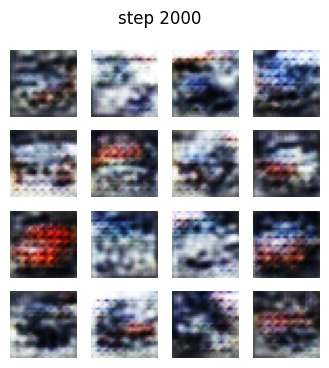

 2500 [D loss 0.593 acc 66%] [G loss 1.329]


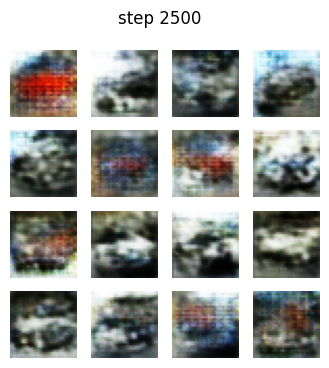

 3000 [D loss 0.601 acc 65%] [G loss 1.253]


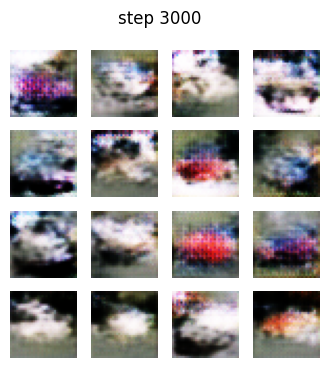

 3500 [D loss 0.609 acc 65%] [G loss 1.191]


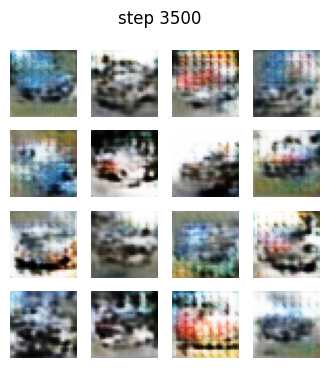


Manual baseline trained 4000 steps in 7.8 min (118 ms/step)


In [5]:
import time
gan = DCGAN(latent_dim=100)
STEPS = 4000           # baseline run
t0 = time.time()
hist = train(gan, X, steps=STEPS, batch_size=64, sample_interval=500)
elapsed = time.time() - t0
print(f"\nManual baseline trained {STEPS} steps in {elapsed/60:.1f} min "
      f"({elapsed/STEPS*1000:.0f} ms/step)")

## 5. Training curves

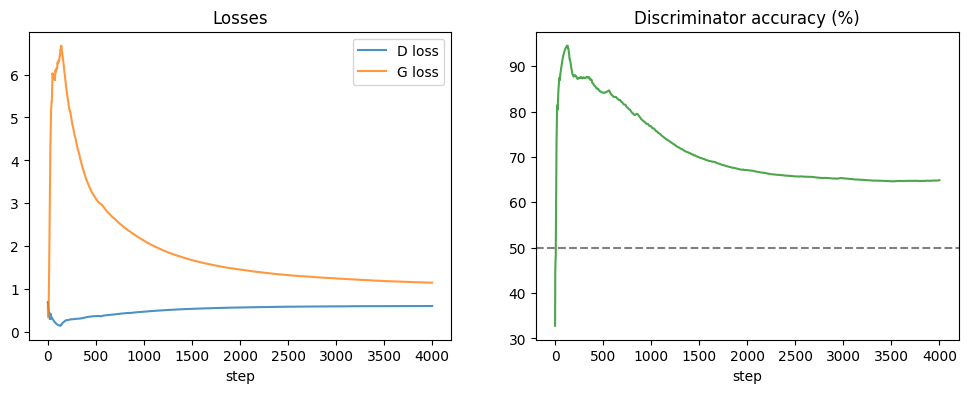

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist['d_loss'], label='D loss', alpha=.8)
ax[0].plot(hist['g_loss'], label='G loss', alpha=.8)
ax[0].set_title('Losses'); ax[0].set_xlabel('step'); ax[0].legend()
ax[1].plot(np.array(hist['d_acc'])*100, color='green', alpha=.7)
ax[1].set_title('Discriminator accuracy (%)'); ax[1].set_xlabel('step')
ax[1].axhline(50, ls='--', color='gray')
plt.show()

## 6. Controlling the noise vector
A GAN learns a smooth mapping from the 100-d latent space to images. We demonstrate this two ways.

### 6a. Latent interpolation
Pick two random noise vectors `z_a`, `z_b` and walk linearly from one to the other. The generated
images should morph **smoothly** — evidence the generator learned a continuous manifold, not a lookup table.

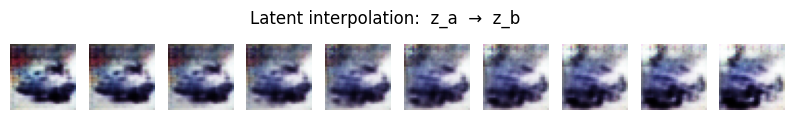

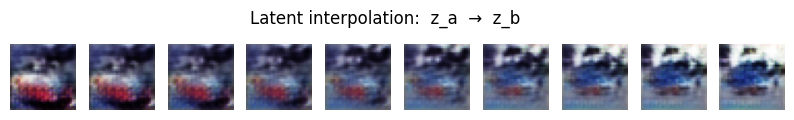

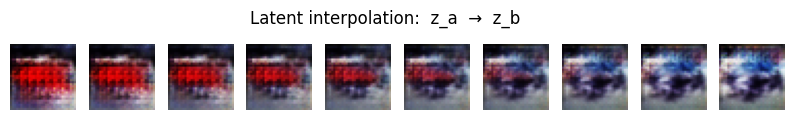

In [7]:
def interpolate(gan, n=10, seed=None):
    rng = np.random.default_rng(seed)
    z_a = rng.normal(0, 1, (1, gan.latent_dim))
    z_b = rng.normal(0, 1, (1, gan.latent_dim))
    alphas = np.linspace(0, 1, n)
    zs = np.vstack([(1 - a) * z_a + a * z_b for a in alphas])
    imgs = 0.5 * gan.generator.predict(zs, verbose=0) + 0.5
    fig, axs = plt.subplots(1, n, figsize=(n, 1.4))
    for i in range(n):
        axs[i].imshow(np.clip(imgs[i], 0, 1)); axs[i].axis('off')
    fig.suptitle("Latent interpolation:  z_a  →  z_b"); plt.show()

for s in [0, 1, 2]:
    interpolate(gan, n=10, seed=s)

### 6b. Single-dimension sweep
Hold a base noise vector fixed and vary **one coordinate** at a time from −3 to +3. Each row shows the
effect of one latent dimension — often a dimension controls a recognizable visual factor
(color, orientation, lighting).

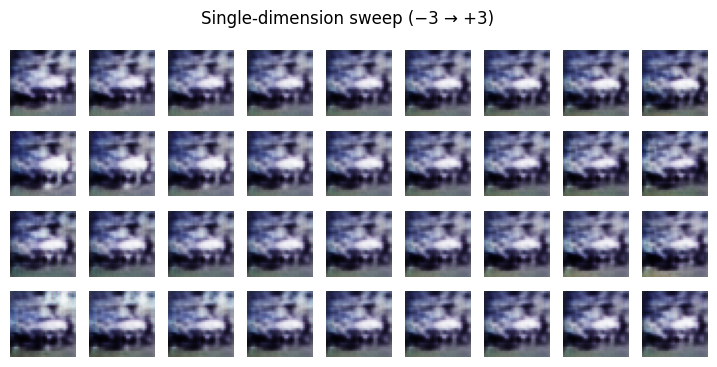

In [8]:
def dim_sweep(gan, dims=(0, 10, 25, 50), n=9, seed=7):
    rng = np.random.default_rng(seed)
    base = rng.normal(0, 1, (1, gan.latent_dim))
    values = np.linspace(-3, 3, n)
    fig, axs = plt.subplots(len(dims), n, figsize=(n, len(dims)))
    for r, d in enumerate(dims):
        zs = np.repeat(base, n, axis=0).copy()
        zs[:, d] = values
        imgs = 0.5 * gan.generator.predict(zs, verbose=0) + 0.5
        for c in range(n):
            axs[r, c].imshow(np.clip(imgs[c], 0, 1)); axs[r, c].axis('off')
        axs[r, 0].set_ylabel(f"dim {d}", rotation=0, labelpad=25, va='center')
    fig.suptitle("Single-dimension sweep (−3 → +3)"); plt.show()

dim_sweep(gan)

## 7. Summary (Manual baseline)
- Converted the class Dense-GAN into a **DCGAN** with `Conv2DTranspose` (generator up-sampling) and
  strided `Conv2D` (discriminator down-sampling), trained on the CIFAR-10 **automobile** class.
- Kept the original class structure and `train_on_batch` loop → straightforward but **not the most efficient**
  (a full `generator.predict` + two `train_on_batch` + one combined `train_on_batch` per step, plus a
  per-step `trainable` toggle that re-traces the train functions).
- **Required a Keras 3 fix** to train at all: separate optimizers for D and the combined model, and toggling
  `discriminator.trainable` each step (see §3). Without it the discriminator is frozen and the GAN produces
  pure noise.
- Demonstrated **noise-vector control** via latent interpolation and per-dimension sweeps.

The `ai_generated/` notebook rebuilds this with a `tf.data` pipeline and a single `@tf.function` training
step (GradientTape), and we compare speed and quality.